# 11 · Incertidumbre, calibración y robustez

Este es un módulo de Neural Networks 1002. Supone los módulos [03 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) (entrenar bien redes profundas: pérdidas, regularización, sobreajuste), [05](https://neural-networks.academy.forwardforecasting.eu/es/) (redes convolucionales y datos de imágenes) y [12](https://neural-networks.academy.forwardforecasting.eu/es/) (el proyecto final, donde hay que confiar en un modelo en un entorno realista).

Una red que dice "esto es un 7" es útil. Una red que dice "esto es un 7, y acierto el 55 % de las veces que suena tan segura" es mucho más útil, porque una persona o un sistema posterior puede decidir qué hacer con ello: aceptar, volver a comprobar o pasar el caso a un experto. Este módulo trata de producir, comprobar y proteger ese segundo tipo de afirmación.

En este cuaderno construirás y medirás, en la CPU de un portátil y con semillas fijas:

1. los dos tipos de incertidumbre, **aleatoria** (ruido en los datos) y **epistémica** (ignorancia del modelo), hechos visibles en un problema de juguete de regresión unidimensional;
2. la **calibración**: diagramas de fiabilidad, el **error de calibración esperado** (ECE, del inglés expected calibration error), por qué las redes modernas son demasiado confiadas y el **escalado por temperatura**;
3. tres maneras de obtener incertidumbre de una red, los **conjuntos profundos** (deep ensembles), el **dropout de Monte Carlo** y una **aproximación de Laplace de la última capa**, comparadas en exactitud, calibración y detección **fuera de distribución** (OOD, out-of-distribution) con el AUROC (área bajo la curva ROC);
4. la **predicción selectiva**: dejar que el modelo se abstenga y cambiar cobertura por exactitud;
5. la **predicción conforme**: conjuntos e intervalos de predicción con una garantía de cobertura que medimos, y vemos romperse bajo cambio de distribución;
6. la **regresión por cuantiles** y la regresión por cuantiles conformada para intervalos de predicción;
7. el **cambio de distribución** con imágenes corrompidas (ruido, desenfoque, rotación);
8. los **ejemplos adversarios**: FGSM (fast gradient sign method, método del signo del gradiente rápido) y PGD (projected gradient descent, descenso de gradiente proyectado) implementados desde cero, una curva medida de exactitud frente a epsilon y el entrenamiento adversario con su coste;
9. el **aumento de datos** como herramienta de robustez, incluido lo que no consigue;
10. una **lista de comprobación** para poner una confianza en producción.

**Contenido**

1. Por qué una predicción necesita una confianza
2. Incertidumbre aleatoria y epistémica en un problema de juguete
3. Calibración y escalado por temperatura
4. Conjuntos, dropout MC y una aproximación de Laplace
5. Predicción selectiva: exactitud frente a cobertura
6. Predicción conforme
7. Regresión por cuantiles e intervalos de predicción
8. Cambio de distribución: imágenes corrompidas
9. Ejemplos adversarios y entrenamiento adversario
10. Aumento de datos como herramienta de robustez
11. Una lista de comprobación para producción
12. Ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [03 Entrenar redes profundas (1001)](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) | la pérdida de entropía cruzada, Adam, el sobreajuste y por qué una red puede memorizar etiquetas erróneas |
| [05 Redes convolucionales (1001)](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) | las imágenes como matrices de píxeles, qué hace un pequeño cambio de la entrada |
| [12 Proyecto final (1001)](https://neural-networks.academy.forwardforecasting.eu/es/12-proyecto-final-caso-real/) | juzgar un modelo con datos distintos de los de entrenamiento |
| [07 Series temporales con redes neuronales (1001)](https://neural-networks.academy.forwardforecasting.eu/es/07-series-temporales/) | pronósticos con intervalos, la idea detrás de la sección 7 |

¿Nuevo en PyTorch? El [curso Python 1001, sección de marcos de IA](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) lo presenta, y su [sección de series temporales](https://python.academy.forwardforecasting.eu/es/12-prevision-de-series-temporales/) trata los intervalos de predicción de pronósticos.

**Datos y en qué se diferencian los juguetes de los sistemas reales.** Usamos los dígitos manuscritos de 8 por 8 píxeles que trae scikit-learn (1797 imágenes, el conjunto de prueba "Optical Recognition of Handwritten Digits" de UCI, de Alpaydin y Kaynak, licencia CC BY 4.0, [doi:10.24432/C50P49](https://doi.org/10.24432/C50P49)), por lo que no se descarga nada, más un problema de regresión generado en el cuaderno. Los sistemas reales tienen imágenes mucho mayores, cambios mucho más ricos que nuestro ruido gaussiano o rotación, y conjuntos de millones de ejemplos; los *métodos* y las *mediciones* se trasladan, los números exactos no. Todo el cuaderno se ejecuta en unos minutos en una CPU.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/11_incertidumbre_calibracion_y_robustez.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: menos de un minuto, con un pico de memoria de menos de 1 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import ndimage
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()

digits = load_digits()
X_ALL = (digits.data / 16.0).astype(np.float32)      # valores de píxel escalados a [0, 1]
Y_ALL = digits.target
print("dígitos:", X_ALL.shape, "clases:", np.unique(Y_ALL))

dígitos: (1797, 64) clases: [0 1 2 3 4 5 6 7 8 9]


## 1. Por qué una predicción necesita una confianza

La última capa de un clasificador produce números llamados **logits** (uno por clase). La **softmax** los convierte en probabilidades que suman uno, y normalmente informamos la mayor como "la confianza" y su clase como "la predicción". Surgen dos preguntas distintas:

* **¿Acierta el modelo?** Eso es la exactitud.
* **¿Significa algo su confianza?** Si reunimos todas las predicciones en las que el modelo dijo "90 %", ¿acierta cerca del 90 % de las veces? Eso es la **calibración**.

Un modelo puede ser exacto y estar mal calibrado, o ser modesto en exactitud y estar perfectamente calibrado. Una confianza calibrada permite fijar un umbral ("enviar a una persona todo lo que esté por debajo del 80 %"), combinar modelos y poner precio al riesgo. Y una confianza vale solo en la situación en que se midió: la **misma** red, ante entradas distintas de sus datos de entrenamiento, suele seguir sonando segura mientras su exactitud se hunde. La mayor parte de este módulo trata de esa brecha y de herramientas que la reducen. Palabras usadas a lo largo del módulo:

| Término | Significado |
|---|---|
| **incertidumbre aleatoria** | aleatoriedad irreducible de los propios datos (una foto borrosa, un sensor ruidoso). Más datos no la eliminan |
| **incertidumbre epistémica** | falta de conocimiento del modelo (pocos datos en una región, o entradas lejos de los datos de entrenamiento). Más datos en esa región sí la reducen |
| **calibración** | acuerdo entre la confianza declarada y la frecuencia observada de acertar |
| **dentro de distribución** (ID), **fuera de distribución** (OOD) | entradas parecidas, o no, a los datos de entrenamiento |
| **cambio de distribución** | los datos vistos en uso difieren de los vistos en entrenamiento |
| **cobertura** | la fracción de casos en que un conjunto o intervalo de predicción contiene la verdad |

## 2. Incertidumbre aleatoria y epistémica en un problema de juguete

Tomemos una entrada $x$ y una salida $y$ con $y = f(x) + \sigma(x)\,\varepsilon$, donde $f(x) = \sin(2.5x)$ es la curva verdadera, $\varepsilon$ es ruido normal estándar, y el nivel de ruido $\sigma(x) = 0.05 + 0.1\,(x + 2)$ **crece con $x$** (se escribe como función de $x$ porque el ruido no es igual en todas partes, lo que se llama *heterocedástico*). Entrenamos solo con $x \in [-2, -0.6] \cup [0.6, 2]$, de modo que hay un **hueco** en el medio y nada fuera de $[-2, 2]$.

Ahora hay dos cosas desconocidas distintas:

* En las regiones con datos la curva se conoce bien pero cada observación es ruidosa, más a la derecha. Es la incertidumbre **aleatoria**: incluso con datos infinitos, $y$ en $x = 1.8$ sigue siendo aleatoria con desviación típica cercana a $0.43$.
* En el hueco y fuera de $[-2, 2]$ no hemos visto datos, así que muchas curvas ajustan igual de bien. Es la incertidumbre **epistémica**: modelos plausibles distintos discrepan.

Para separarlas usamos un **conjunto** pequeño de $M = 5$ redes. Cada una produce una media $\mu_m(x)$ y una varianza $v_m(x)$ y se entrena con la **log-verosimilitud negativa gaussiana** (NLL, negative log-likelihood), $\tfrac12\left[\ln v + (y-\mu)^2 / v\right]$, de modo que aprende tanto la curva como su propio nivel de ruido. La descomposición (Kendall y Gal, 2017) es entonces

$$\underbrace{\sigma_\text{ale}^2(x) = \frac1M \sum_m v_m(x)}_{\text{ruido medio predicho}}, \qquad \underbrace{\sigma_\text{epi}^2(x) = \frac1M \sum_m \big(\mu_m(x) - \bar\mu(x)\big)^2}_{\text{discrepancia entre miembros}}, \qquad \sigma_\text{tot}^2 = \sigma_\text{ale}^2 + \sigma_\text{epi}^2,$$

donde $\bar\mu = \frac1M\sum_m \mu_m$ es la media del conjunto (la ley de la varianza total).

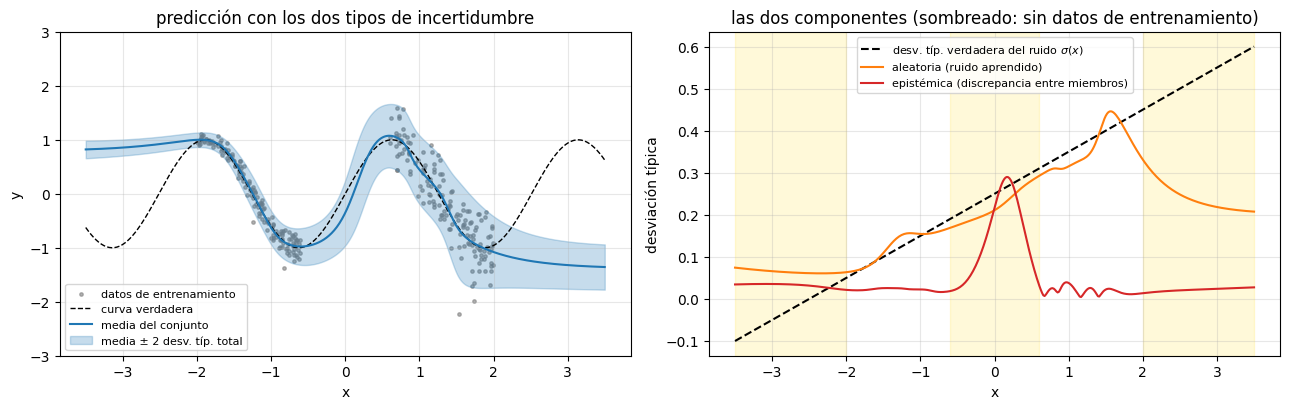

región                       ruido real  aleatoria epistémica
región con datos (0.6<|x|<2)      0.250      0.241      0.020
hueco (|x|<0.5)                   0.250      0.219      0.162
extrapolación (|x|>2.5)           0.250      0.144      0.029
correlación del ruido aprendido con el ruido verdadero en la región con datos: 0.979
tiempo 62 s


In [2]:
def f_true(x): return np.sin(2.5 * x)
def s_true(x): return 0.05 + 0.1 * (x + 2.0)

rng = np.random.default_rng(0)
x_tr = np.concatenate([rng.uniform(-2, -0.6, 150), rng.uniform(0.6, 2, 150)])
y_tr = f_true(x_tr) + s_true(x_tr) * rng.standard_normal(x_tr.size)
xt = torch.tensor(x_tr, dtype=torch.float32)[:, None]
yt = torch.tensor(y_tr, dtype=torch.float32)[:, None]

def fit_gauss(seed, steps=1000):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 2))
    opt = torch.optim.Adam(net.parameters(), lr=5e-3)
    for _ in range(steps):
        out = net(xt); mu, lv = out[:, :1], out[:, 1:].clamp(-9, 3)
        loss = (0.5 * (lv + (yt - mu) ** 2 / lv.exp())).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return net

t0 = time.time()
members = [fit_gauss(s) for s in range(5)]
xg = np.linspace(-3.5, 3.5, 400)
with torch.no_grad():
    outs = torch.stack([m(torch.tensor(xg, dtype=torch.float32)[:, None]) for m in members])   # (M, N, 2)
mus = outs[:, :, 0].numpy()
vs = outs[:, :, 1].clamp(-9, 3).exp().numpy()
mu_bar = mus.mean(0)
sig_ale = np.sqrt(vs.mean(0))
sig_epi = mus.std(0)
sig_tot = np.sqrt(sig_ale ** 2 + sig_epi ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].scatter(x_tr, y_tr, s=6, c="gray", alpha=0.6, label="datos de entrenamiento")
ax[0].plot(xg, f_true(xg), "k--", lw=1, label="curva verdadera")
ax[0].plot(xg, mu_bar, c="C0", label="media del conjunto")
ax[0].fill_between(xg, mu_bar - 2 * sig_tot, mu_bar + 2 * sig_tot, color="C0", alpha=0.25, label="media ± 2 desv. típ. total")
ax[0].set_ylim(-3, 3); ax[0].set_xlabel("x"); ax[0].set_ylabel("y"); ax[0].legend(loc="lower left", fontsize=8)
ax[0].set_title("predicción con los dos tipos de incertidumbre")
ax[1].plot(xg, s_true(xg), "k--", label="desv. típ. verdadera del ruido $\\sigma(x)$")
ax[1].plot(xg, sig_ale, c="C1", label="aleatoria (ruido aprendido)")
ax[1].plot(xg, sig_epi, c="C3", label="epistémica (discrepancia entre miembros)")
ax[1].axvspan(-0.6, 0.6, color="gold", alpha=0.15); ax[1].axvspan(-3.5, -2, color="gold", alpha=0.15); ax[1].axvspan(2, 3.5, color="gold", alpha=0.15)
ax[1].set_xlabel("x"); ax[1].set_ylabel("desviación típica"); ax[1].legend(fontsize=8); ax[1].set_title("las dos componentes (sombreado: sin datos de entrenamiento)")
plt.tight_layout(); plt.show()

reg = {"región con datos (0.6<|x|<2)": (np.abs(xg) > 0.6) & (np.abs(xg) < 2),
       "hueco (|x|<0.5)": np.abs(xg) < 0.5,
       "extrapolación (|x|>2.5)": np.abs(xg) > 2.5}
print(f"{'región':28s} {'ruido real':>10s} {'aleatoria':>10s} {'epistémica':>10s}")
for k, m in reg.items():
    print(f"{k:28s} {s_true(xg[m]).mean():10.3f} {sig_ale[m].mean():10.3f} {sig_epi[m].mean():10.3f}")
d = reg["región con datos (0.6<|x|<2)"]
print("correlación del ruido aprendido con el ruido verdadero en la región con datos:", round(float(np.corrcoef(sig_ale[d], s_true(xg[d]))[0, 1]), 3))
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** La estimación del nivel de ruido sigue al verdadero en la región con datos (correlación 0.98 con $\sigma(x)$, media 0.24 frente a un 0.25 verdadero), así que la parte aleatoria se aprende bien donde hay datos. La parte epistémica es pequeña en la región con datos (0.020) y **ocho veces mayor en el hueco** (0.162), como debe ser: los miembros coinciden donde han visto datos y discrepan donde no. Con honestidad, la extrapolación fuera de $[-2, 2]$ es un **punto débil**: la desviación típica epistémica ahí es solo 0.029, porque estas redes tanh se aplanan todas de manera parecida, así que cinco miembros coinciden en una continuación equivocada, y el ruido aprendido (0.144) queda por debajo del ruido verdadero. La discrepancia entre miembros subestima la ignorancia cuando los miembros comparten el mismo sesgo inductivo. Un solo conjunto de semillas; los números se mueven algo con las semillas.

**En qué se diferencia el juguete de los sistemas reales.** Las redes reales tienen millones de pesos, de modo que un puñado de miembros del conjunto muestrea muy escasamente el espacio de modelos plausibles; y el ruido real rara vez es gaussiano. La separación depende además de que el modelo pueda representar el ruido: una red entrenada con error cuadrático simple no tiene salida aleatoria alguna.

## 3. Calibración y escalado por temperatura

Para un clasificador con clase predicha $\hat y$ y confianza $\hat p = \max_k p_k$ (la mayor probabilidad softmax), el modelo está **perfectamente calibrado** cuando $P(\hat y = y \mid \hat p = c) = c$ para cada nivel de confianza $c$. Lo estimamos ordenando las predicciones en $B$ intervalos de confianza de igual anchura $b$ y comparando, en cada uno, la **exactitud** $\mathrm{acc}(b)$ con la **confianza** media $\mathrm{conf}(b)$. Un **diagrama de fiabilidad** representa $\mathrm{acc}(b)$ frente a $\mathrm{conf}(b)$ (la diagonal es lo perfecto), y el **error de calibración esperado** lo resume,

$$\mathrm{ECE} = \sum_{b=1}^{B} \frac{n_b}{n}\,\big|\mathrm{acc}(b) - \mathrm{conf}(b)\big|,$$

donde $n_b$ es el número de predicciones del intervalo $b$ y $n$ el total (usamos $B = 15$). También informamos la **NLL** (el promedio de $-\ln p_{\text{clase verdadera}}$), una puntuación propia que premia tanto la exactitud como las probabilidades honestas.

**Por qué las redes modernas son demasiado confiadas.** Guo et al. (2017) mostraron que las redes profundas entrenadas hasta pérdida de entrenamiento casi nula se vuelven demasiado confiadas: la entropía cruzada sigue premiando logits mayores mucho después de que todos los ejemplos de entrenamiento estén bien clasificados, así que las probabilidades se empujan hacia 0 y 1 sin importar su fiabilidad con datos nuevos. Para hacerlo visible en un problema pequeño entrenamos una red con solo 500 dígitos, **el 25 % con etiqueta errónea** (una situación realista: etiquetar nunca es perfecto), el tiempo suficiente para memorizarlos. El conjunto de prueba está limpio.

El **escalado por temperatura** es el arreglo más simple. Se dividen los logits $z$ entre un número $T > 0$ antes de la softmax, $p = \mathrm{softmax}(z / T)$, y se elige $T$ minimizando la NLL en un conjunto de validación apartado. $T > 1$ suaviza las probabilidades. El orden de las clases no cambia, así que **la exactitud no se toca**; solo cambia la confianza.

etiquetas realmente cambiadas: 98 de 500


temperatura ajustada T = 2.51
                   exactitud     NLL     ECE conf. media
sin escalar            0.782   1.148   0.138      0.920
con temperatura        0.782   0.720   0.029      0.770


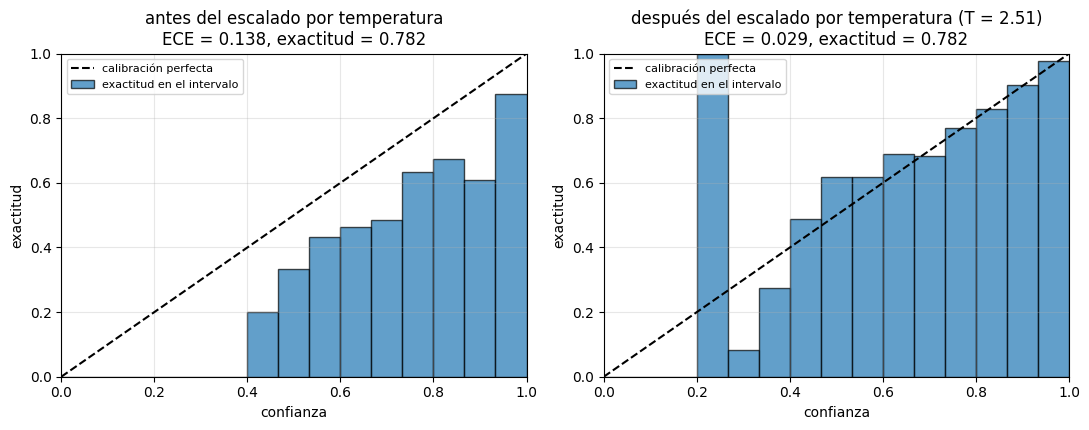

tiempo 6 s


In [3]:
def softmax_np(z):
    z = z - z.max(-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(-1, keepdims=True)

def ece_score(p, y, bins=15):
    conf = p.max(1); correct = p.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e

def nll_score(p, y):
    return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())

def make_mlp(d_out, p=0.0, h=128):
    return nn.Sequential(nn.Linear(64, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, d_out))

def fit(X, y, seed, d_out=10, epochs=100, lr=3e-3, p=0.0):
    # Adam con lote completo sobre un conjunto de entrenamiento pequeño
    torch.manual_seed(seed)
    m = make_mlp(d_out, p); opt = torch.optim.Adam(m.parameters(), lr=lr)
    Xt = torch.as_tensor(X, dtype=torch.float32); yt_ = torch.as_tensor(y)
    m.train()
    for _ in range(epochs):
        loss = F.cross_entropy(m(Xt), yt_)
        opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

def logits_of(m, X):
    with torch.no_grad():
        return m(torch.as_tensor(X, dtype=torch.float32)).numpy()

def fit_temperature(z_val, y_val):
    logT = torch.zeros(1, requires_grad=True)
    zt, yv = torch.as_tensor(z_val), torch.as_tensor(y_val)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)
    def closure():
        opt.zero_grad(); l = F.cross_entropy(zt / logT.exp(), yv); l.backward(); return l
    opt.step(closure)
    return float(logT.exp())

def reliability(ax, p, y, title, bins=15):
    conf = p.max(1); correct = p.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1); centres = (edges[:-1] + edges[1:]) / 2
    accs = np.full(bins, np.nan)
    cnt = np.zeros(bins)
    for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        m = (conf > lo) & (conf <= hi); cnt[i] = m.sum()
        if m.any(): accs[i] = correct[m].mean()
    ax.bar(centres, np.nan_to_num(accs), width=1 / bins, edgecolor="k", alpha=0.7, color="C0", label="exactitud en el intervalo")
    ax.plot([0, 1], [0, 1], "k--", label="calibración perfecta")
    ax.set_xlabel("confianza"); ax.set_ylabel("exactitud"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(f"{title}\nECE = {ece_score(p, y, bins):.3f}, exactitud = {correct.mean():.3f}"); ax.legend(loc="upper left", fontsize=8)

# partición de 10 clases: 500 de entrenamiento (25 % de etiquetas erróneas), 300 de validación, el resto de prueba
idx_tr, idx_rest = train_test_split(np.arange(len(Y_ALL)), train_size=500, stratify=Y_ALL, random_state=0)
idx_va, idx_te = train_test_split(idx_rest, train_size=300, stratify=Y_ALL[idx_rest], random_state=0)
Xtr, ytr_clean = X_ALL[idx_tr], Y_ALL[idx_tr]
Xva, yva, Xte, yte = X_ALL[idx_va], Y_ALL[idx_va], X_ALL[idx_te], Y_ALL[idx_te]
rng = np.random.default_rng(0)
ytr_noisy = ytr_clean.copy(); flip = rng.random(len(ytr_noisy)) < 0.25
ytr_noisy[flip] = rng.integers(0, 10, flip.sum())
print("etiquetas realmente cambiadas:", int((ytr_noisy != ytr_clean).sum()), "de", len(ytr_noisy))

t0 = time.time()
net_noisy = fit(Xtr, ytr_noisy, seed=0, epochs=300)
z_va, z_te = logits_of(net_noisy, Xva), logits_of(net_noisy, Xte)
T = fit_temperature(z_va, yva)
p_raw, p_ts = softmax_np(z_te), softmax_np(z_te / T)
print(f"temperatura ajustada T = {T:.2f}")
print(f"{'':18s} {'exactitud':>9s} {'NLL':>7s} {'ECE':>7s} {'conf. media':>10s}")
for name, p in [("sin escalar", p_raw), ("con temperatura", p_ts)]:
    print(f"{name:18s} {(p.argmax(1) == yte).mean():9.3f} {nll_score(p, yte):7.3f} {ece_score(p, yte):7.3f} {p.max(1).mean():10.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
reliability(ax[0], p_raw, yte, "antes del escalado por temperatura")
reliability(ax[1], p_ts, yte, f"después del escalado por temperatura (T = {T:.2f})")
plt.tight_layout(); plt.show()
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** La red acierta solo el 78 % de las veces, pero su confianza media es del 92 %: **demasiado confiada por 14 puntos** (ECE 0.138, NLL 1.15). Una sola temperatura ajustada, $T = 2.51$, baja la confianza media al 77 %, cerca de la exactitud, el ECE a 0.029 y la NLL a 0.72, con **exactitud idéntica** (0.782). El diagrama de fiabilidad pasa a la diagonal. El escalado por temperatura no puede hacer el modelo más exacto y aplica el mismo suavizado a toda entrada; solo repara el promedio.

**En qué se diferencia el juguete de los sistemas reales.** El 25 % de ruido en las etiquetas es una exageración elegida para que la sobreconfianza se vea en un problema diminuto; las redes grandes con conjuntos grandes y limpios son demasiado confiadas por razones más sutiles (la profundidad, el ancho, la regularización por pesos y la normalización lo cambian, véase Guo et al., 2017). Una cautela más: el conjunto de validación que ajusta $T$ es pequeño aquí, y una $T$ ajustada con datos limpios **no** se traslada a datos con cambio, lo que medimos en las secciones 6 y 8.

## 4. Conjuntos, dropout MC y una aproximación de Laplace

El escalado por temperatura arregla la confianza *media* pero trata igual todas las entradas. Queremos una incertidumbre que sea **mayor para las entradas que el modelo no ha aprendido**. Tres maneras prácticas, todas de la familia de aproximar la **distribución predictiva bayesiana** (promediar las predicciones de muchas redes plausibles en lugar de fiarse de una):

* **Conjunto profundo** (Lakshminarayanan et al., 2017). Se entrenan $M$ redes desde inicializaciones aleatorias distintas y se promedian sus salidas softmax. Simple y potente, pero $M$ veces el coste de entrenamiento y de predicción. Usamos $M = 5$.
* **Dropout de Monte Carlo (MC)** (Gal y Ghahramani, 2016). Se entrena con dropout (poner a cero unidades al azar) y se **mantiene el dropout activo al predecir**: cada una de las $S = 30$ pasadas hacia adelante estocásticas es una red adelgazada distinta, y se promedian. Un entrenamiento, $S$ veces el coste de predicción.
* **Aproximación de Laplace de la última capa** (véase Daxberger et al., 2021). Se conserva una red entrenada, se tratan todas las capas salvo la última como un extractor de características fijo $\phi(x)$ y se pone una distribución gaussiana sobre los **pesos de la última capa** $W$ alrededor de su valor entrenado $\hat W$ con covarianza $\Sigma = \left(\sum_i \phi_i\phi_i^\top \otimes \mathrm{diag}(p_i) - p_ip_i^\top + \lambda I\right)^{-1}$ (la inversa de la curvatura de la pérdida en el conjunto de entrenamiento más una precisión a priori $\lambda$; $\otimes$ es el producto de Kronecker). Se muestrean pesos y se promedia la softmax. Es barata (una inversión de matriz) pero solo captura la incertidumbre de la última capa.

**El experimento.** Para medir si la incertidumbre es útil hacemos un problema de 7 clases: se entrena solo con los dígitos 0 a 6. Luego probamos en tres conjuntos:

1. imágenes de prueba **dentro de distribución** (dígitos 0 a 6, limpias);
2. **clases excluidas**: imágenes de los dígitos 7, 8 y 9, que el modelo nunca ha visto y no puede nombrar correctamente (un caso OOD puro);
3. **conjunto con cambio**: las imágenes de prueba dentro de distribución corrompidas con ruido fuerte de píxeles (desviación típica 0.4, valores recortados a $[0,1]$), las mismas clases pero otro "sensor".

La detección OOD se puntúa con el **AUROC**: la probabilidad de que una entrada OOD al azar reciba una "puntuación de incertidumbre" mayor que una dentro de distribución al azar (1.0 perfecto, 0.5 azar). La puntuación es $1 - \hat p$ (uno menos la mayor probabilidad promediada, la **máxima probabilidad softmax**, MSP, la referencia de Hendrycks y Gimpel, 2017). Para los conjuntos y el dropout MC probamos además la **información mutua** $\mathrm{MI} = H(\bar p) - \tfrac1M\sum_m H(p_m)$, donde $H$ es la entropía y $\bar p$ el promedio de las probabilidades de los miembros: es grande cuando los miembros *discrepan*, la parte epistémica. Todo se repite con 3 particiones e inicializaciones aleatorias, porque con conjuntos de prueba pequeños una ejecución es ruidosa.

In [4]:
def entropy(p): return -(p * np.log(p + 1e-12)).sum(-1)

def laplace_sampler(net, Xtr_, prior_prec, n_samples=60, seed=0):
    # gaussiana sobre los pesos de la última capa (con sesgo), curvatura del conjunto de entrenamiento
    with torch.no_grad():
        feats = net[:-1](torch.as_tensor(Xtr_, dtype=torch.float32))
        phi = torch.cat([feats, torch.ones(len(feats), 1)], 1)                 # (n, D)
        p = torch.softmax(net[-1](feats), 1)                                   # (n, K)
        W = torch.cat([net[-1].weight, net[-1].bias[:, None]], 1)              # (K, D)
        K, D = W.shape
        A = torch.diag_embed(p) - p[:, :, None] * p[:, None, :]                # (n, K, K)
        H = torch.einsum("ikl,ij,im->kjlm", A, phi, phi).reshape(K * D, K * D) + prior_prec * torch.eye(K * D)
        cov = torch.linalg.inv(H); cov = (cov + cov.T) / 2
        L = torch.linalg.cholesky(cov + 1e-7 * torch.eye(K * D))
        g = torch.Generator().manual_seed(seed)
        Ws = (W.reshape(-1)[:, None] + L @ torch.randn(K * D, n_samples, generator=g)).T.reshape(n_samples, K, D)
    def predict(X):
        with torch.no_grad():
            f = net[:-1](torch.as_tensor(X, dtype=torch.float32)); f = torch.cat([f, torch.ones(len(f), 1)], 1)
            return torch.softmax(torch.einsum("nd,skd->snk", f, Ws), -1).numpy()    # (S, n, K)
    return predict

def mc_dropout_predict(net, X, S=30, seed=0):
    torch.manual_seed(seed); net.train()
    with torch.no_grad():
        out = torch.stack([torch.softmax(net(torch.as_tensor(X, dtype=torch.float32)), -1) for _ in range(S)]).numpy()
    net.eval(); return out

def corrupt_noise(X, sigma, seed=0):
    r = np.random.default_rng(seed)
    return np.clip(X + sigma * r.standard_normal(X.shape), 0, 1).astype(np.float32)

METHODS = ["single", "single + temperature", "MC dropout", "deep ensemble (5)", "last-layer Laplace"]

def run_seed(seed):
    ins = Y_ALL < 7
    Xi, yi, Xo = X_ALL[ins], Y_ALL[ins], X_ALL[~ins]
    Xtr_, Xrest, ytr_, yrest = train_test_split(Xi, yi, train_size=400, stratify=yi, random_state=seed)
    Xva_, Xte_, yva_, yte_ = train_test_split(Xrest, yrest, train_size=0.4, stratify=yrest, random_state=seed)
    sets = {"id": Xte_, "ood": Xo, "shift": corrupt_noise(Xte_, 0.4, seed), "mix": corrupt_noise(Xte_, 0.25, seed + 100)}
    single = fit(Xtr_, ytr_, seed, d_out=7)
    Tm = fit_temperature(logits_of(single, Xva_), yva_)
    drop = fit(Xtr_, ytr_, seed, d_out=7, p=0.2)
    ens = [fit(Xtr_, ytr_, seed * 100 + k, d_out=7) for k in range(5)]
    # elegir la precisión a priori de Laplace por la NLL de validación
    best = None
    for lam in [1, 10, 100, 1000]:
        pr = laplace_sampler(single, Xtr_, lam, seed=seed)
        nll = nll_score(pr(Xva_).mean(0), yva_)
        if best is None or nll < best[0]: best = (nll, lam, pr)
    lap = best[2]
    pred = {}
    for name, X in sets.items():
        pred[name] = {
            "single": softmax_np(logits_of(single, X))[None],
            "single + temperature": softmax_np(logits_of(single, X) / Tm)[None],
            "MC dropout": mc_dropout_predict(drop, X, seed=seed),
            "deep ensemble (5)": np.stack([softmax_np(logits_of(m, X)) for m in ens]),
            "last-layer Laplace": lap(X),
        }
    return {"pred": pred, "y": yte_, "T": Tm, "lam": best[1]}

t0 = time.time()
runs = [run_seed(s) for s in range(3)]
print(f"entrenadas {3 * 7} redes en {time.time() - t0:.0f} s; temperaturas {[round(r['T'], 2) for r in runs]}; precisiones a priori de Laplace {[r['lam'] for r in runs]}")

def mean_std(v): return f"{np.mean(v):.3f}±{np.std(v):.3f}"
cols = ["accuracy", "NLL", "ECE", "AUROC class MSP", "AUROC shift MSP", "AUROC class MI", "AUROC shift MI"]
print(f"{'method':22s} " + " ".join(f"{c:>15s}" for c in cols))
table = {}
for meth in METHODS:
    vals = {c: [] for c in cols}
    for r in runs:
        P = r["pred"]; y = r["y"]; pid = P["id"][meth].mean(0)
        vals["accuracy"].append((pid.argmax(1) == y).mean()); vals["NLL"].append(nll_score(pid, y)); vals["ECE"].append(ece_score(pid, y))
        for key, nm in [("ood", "class"), ("shift", "shift")]:
            po = P[key][meth].mean(0)
            s_id, s_o = 1 - pid.max(1), 1 - po.max(1)
            vals[f"AUROC {nm} MSP"].append(roc_auc_score(np.r_[np.zeros(len(s_id)), np.ones(len(s_o))], np.r_[s_id, s_o]))
            if P["id"][meth].shape[0] > 1:
                mi = lambda S: entropy(S.mean(0)) - entropy(S).mean(0)
                a, b = mi(P["id"][meth]), mi(P[key][meth])
                vals[f"AUROC {nm} MI"].append(roc_auc_score(np.r_[np.zeros(len(a)), np.ones(len(b))], np.r_[a, b]))
    table[meth] = vals
    print(f"{meth:22s} " + " ".join(f"{mean_std(vals[c]) if vals[c] else '-':>15s}" for c in cols))

entrenadas 21 redes en 38 s; temperaturas [1.64, 1.16, 1.51]; precisiones a priori de Laplace [100, 1000, 100]
method                        accuracy             NLL             ECE AUROC class MSP AUROC shift MSP  AUROC class MI  AUROC shift MI
single                     0.977±0.009     0.090±0.026     0.015±0.004     0.940±0.012     0.796±0.012               -               -
single + temperature       0.977±0.009     0.079±0.018     0.009±0.002     0.944±0.011     0.798±0.012               -               -
MC dropout                 0.979±0.008     0.072±0.020     0.010±0.002     0.939±0.016     0.814±0.012     0.933±0.016     0.812±0.010


deep ensemble (5)          0.975±0.009     0.082±0.026     0.013±0.006     0.946±0.009     0.814±0.012     0.953±0.009     0.854±0.008
last-layer Laplace         0.978±0.009     0.084±0.021     0.011±0.001     0.939±0.010     0.796±0.012     0.934±0.009     0.794±0.014


**Lectura.** Con dígitos limpios dentro de distribución todos los métodos son exactos (97.5 a 97.9 %) y están bien calibrados (ECE cerca de 0.01), porque el problema limpio es fácil; **las diferencias de exactitud, NLL y ECE entre métodos están dentro de una desviación típica entre semillas**, así que no podemos ordenarlos ahí (el escalado por temperatura y el dropout MC tienen la menor NLL, 0.079 y 0.072, frente a 0.090 de la red simple, una mejora pequeña). Para detectar las **clases excluidas** todos los métodos llegan a un AUROC de 0.94 a 0.95 con la máxima probabilidad, y la información mutua del conjunto es marginalmente la mejor (0.953), otra vez dentro del ruido. La diferencia más clara está en el **conjunto con cambio**: con la máxima probabilidad el conjunto y el dropout MC llegan a 0.814 frente a 0.796 de la red simple y de Laplace, y la **información mutua del conjunto** da 0.854 (dispersión 0.008), una mejora mayor que el ruido de semillas. La aproximación de Laplace de la última capa, que solo modela la última capa, no ayudó en ninguna medida aquí. Las imágenes con cambio son difíciles de señalar para todos los métodos (AUROC como máximo 0.85).

**En qué se diferencia el juguete de los sistemas reales.** La detección OOD real es mucho más difícil: las clases no vistas en imágenes naturales se *parecen* a las vistas, y los cambios son semánticos, no ruido aditivo. Ovadia et al. (2019) evaluaron estos mismos métodos en grandes conjuntos de imágenes, texto y datos tabulares bajo cambio y hallaron que el conjunto es el más robusto, con todos los métodos degradándose al crecer el cambio; nuestro resultado coincide en la dirección, pero nuestros números salen de dígitos de 8 por 8 y 3 semillas.

## 5. Predicción selectiva: exactitud frente a cobertura

La calibración y la incertidumbre se vuelven útiles cuando guían una decisión. La más simple es la **opción de rechazo** (también llamada clasificación selectiva, Geifman y El-Yaniv, 2017): responder solo cuando la confianza supera un umbral y abstenerse en caso contrario (pasar el caso a una persona). Dos números describen cada umbral:

* **cobertura**: la fracción de entradas que el modelo responde;
* **exactitud selectiva**: la exactitud en las respondidas.

Al barrer el umbral se obtiene la curva de **exactitud frente a cobertura**. Una buena confianza ordena los errores por debajo de los aciertos, así que la exactitud sube al bajar la cobertura. La línea discontinua del **oráculo** es lo mejor posible: rechaza primero exactamente las respuestas erróneas. Ordenamos por la máxima probabilidad promediada de cada método y evaluamos en una mezcla 50/50 de imágenes de prueba limpias y las mismas imágenes con ruido moderado (desviación típica 0.25), el tipo de tráfico mezclado que ve un sistema desplegado. También informamos el **AURC** (área bajo la curva riesgo-cobertura, donde el riesgo es la tasa de error; menor es mejor) promediado sobre las tres semillas.

método                   ex@100%    ex@80%    ex@50%   AURC (menor=mejor)
single                     0.955     0.992     0.998               0.0054
single + temperature       0.955     0.992     0.998               0.0054
MC dropout                 0.957     0.993     0.999               0.0042
deep ensemble (5)          0.952     0.995     0.999               0.0046
last-layer Laplace         0.956     0.991     0.998               0.0057


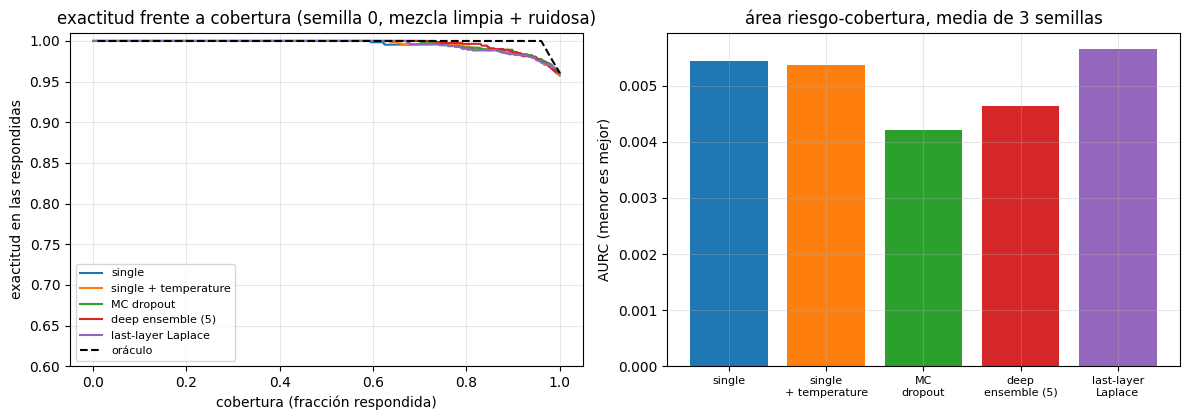

In [5]:
def sel_curve(p, y):
    order = np.argsort(-p.max(1)); correct = (p.argmax(1) == y)[order]
    cov = np.arange(1, len(y) + 1) / len(y)
    return cov, np.cumsum(correct) / np.arange(1, len(y) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
r0 = runs[0]; y_mix = np.r_[r0["y"], r0["y"]]
for k, meth in enumerate(METHODS):
    p = np.concatenate([r0["pred"]["id"][meth].mean(0), r0["pred"]["mix"][meth].mean(0)])
    cov, acc = sel_curve(p, y_mix); ax[0].plot(cov, acc, c=f"C{k}", label=meth)
base = (p.argmax(1) == y_mix).mean()
cov = np.linspace(0.01, 1, 200); ax[0].plot(cov, np.minimum(1, base / cov), "k--", label="oráculo")
ax[0].set_xlabel("cobertura (fracción respondida)"); ax[0].set_ylabel("exactitud en las respondidas"); ax[0].set_title("exactitud frente a cobertura (semilla 0, mezcla limpia + ruidosa)")
ax[0].set_ylim(0.6, 1.01); ax[0].legend(fontsize=8, loc="lower left")

print(f"{'método':22s} {'ex@100%':>9s} {'ex@80%':>9s} {'ex@50%':>9s} {'AURC (menor=mejor)':>20s}")
res = {}
for meth in METHODS:
    a100, a80, a50, aurc = [], [], [], []
    for r in runs:
        yy = np.r_[r["y"], r["y"]]
        p = np.concatenate([r["pred"]["id"][meth].mean(0), r["pred"]["mix"][meth].mean(0)])
        cov, acc = sel_curve(p, yy)
        a100.append(acc[-1]); a80.append(acc[int(0.8 * len(acc)) - 1]); a50.append(acc[int(0.5 * len(acc)) - 1])
        aurc.append(np.mean(1 - acc))
    res[meth] = np.mean(aurc)
    print(f"{meth:22s} {np.mean(a100):9.3f} {np.mean(a80):9.3f} {np.mean(a50):9.3f} {np.mean(aurc):20.4f}")
ax[1].bar(range(len(METHODS)), [res[m] for m in METHODS], color=[f"C{k}" for k in range(len(METHODS))])
ax[1].set_xticks(range(len(METHODS))); ax[1].set_xticklabels([m.replace(" ", "\n", 1) for m in METHODS], fontsize=8)
ax[1].set_ylabel("AURC (menor es mejor)"); ax[1].set_title("área riesgo-cobertura, media de 3 semillas")
plt.tight_layout(); plt.show()

**Lectura.** Rechazar el 20 % menos confiado del tráfico mezclado sube la exactitud de cerca de 95.5 % a 99.1 a 99.5 %, y quedarse solo con el 50 % más confiado da cerca de 99.8 %, próximo al oráculo. Los métodos difieren poco: el dropout MC (AURC 0.0042) y el conjunto (0.0046) son algo mejores que la red simple (0.0054) y Laplace (0.0057), pero esas diferencias corresponden a unos pocos errores por mil respuestas, así que trata el orden como una sugerencia, no como algo establecido. El escalado por temperatura da **exactamente la misma curva** que la red sin escalar: reescala todas las confianzas con la misma función monótona y por tanto no puede cambiar su orden, que es todo lo que usa la predicción selectiva.

## 6. Predicción conforme

La calibración dice "las probabilidades son más o menos correctas en promedio". La **predicción conforme** (Angelopoulos y Bates, 2021) da una *garantía* válida para cualquier modelo y cualquier distribución de datos, **siempre que los datos de calibración y de prueba sean intercambiables** (aproximadamente: extraídos de la misma manera). En lugar de una etiqueta devuelve un **conjunto de predicción** $C(x)$ que contiene la etiqueta verdadera con probabilidad al menos $1-\alpha$, donde $\alpha$ es la tasa de error que eliges (usamos $\alpha = 0.1$, apuntando a una cobertura del 90 %).

**Conforme dividida (split) para clasificación.** Se aparta un **conjunto de calibración** de $n$ ejemplos etiquetados con los que el modelo no entrenó.

1. A cada ejemplo de calibración se le da una **puntuación de no conformidad** $s_i = 1 - p_{y_i}(x_i)$, uno menos la probabilidad que el modelo asignó a la clase *verdadera* (alta = el modelo encontró sorprendente la verdad).
2. Sea $\hat q$ la $\lceil (n+1)(1-\alpha) \rceil$-ésima menor puntuación (un cuantil ligeramente inflado).
3. Para una entrada nueva se devuelven todas las clases $k$ con $1 - p_k(x) \le \hat q$.

La garantía es $1-\alpha \le P(y \in C(x)) \le 1 - \alpha + 1/(n+1)$ en promedio sobre las extracciones de calibración, y la cobertura para un conjunto de calibración concreto sigue una distribución Beta. Verificamos ambas cosas repitiendo todo el procedimiento con 300 conjuntos de calibración aleatorios. El **tamaño** del conjunto es el precio: un modelo confiado devuelve una clase, uno inseguro devuelve varias. Luego rompemos el supuesto: calibramos con imágenes limpias y probamos con ruidosas.

modelo limpio de 10 clases: exactitud del conjunto 0.960, ECE 0.018, tamaño del conjunto 1297
objetivo 1-alpha = 0.90; cobertura media teórica 0.900, rango 5-95 % [0.871, 0.927]
medido sobre 300 conjuntos de calibración: media 0.901, rango 5-95 % [0.865, 0.933], tamaño medio del conjunto 0.91


desv. ruido exactitud cobertura (cal. limpia)    tamaño  cobertura (recalibrada)
      0.0     0.960                  0.905      0.92                    0.905
      0.1     0.938                  0.869      0.89                    0.901
      0.2     0.891                  0.793      0.83                    0.901
      0.3     0.788                  0.651      0.74                    0.900
      0.4     0.664                  0.513      0.67                    0.902
      0.5     0.537                  0.383      0.60                    0.904


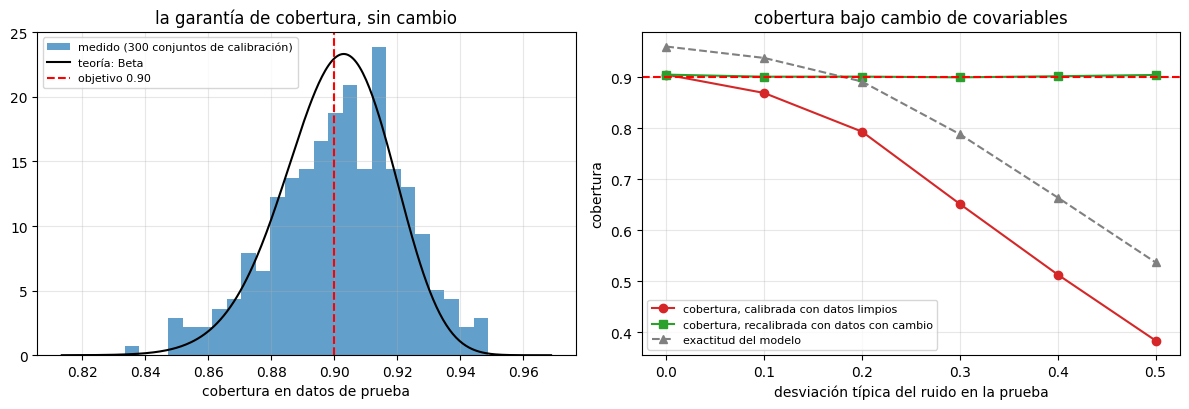

tiempo 9 s


In [6]:
def conformal_qhat(p_cal, y_cal, alpha):
    s = np.sort(1 - p_cal[np.arange(len(y_cal)), y_cal]); n = len(s)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    return s[min(k, n) - 1], k

def conformal_sets(p, qhat): return (1 - p) <= qhat

t0 = time.time()
# un modelo limpio de 10 clases (etiquetas limpias) usado aquí y en las secciones 8 a 10
idx10_tr, idx10_pool = train_test_split(np.arange(len(Y_ALL)), train_size=500, stratify=Y_ALL, random_state=1)
X10, y10 = X_ALL[idx10_tr], Y_ALL[idx10_tr]
Xpool, ypool = X_ALL[idx10_pool], Y_ALL[idx10_pool]
net10 = fit(X10, y10, seed=0)
ens10 = [net10] + [fit(X10, y10, seed=k) for k in range(1, 5)]
p_pool = softmax_np(logits_of(net10, Xpool))
print(f"modelo limpio de 10 clases: exactitud del conjunto {(p_pool.argmax(1) == ypool).mean():.3f}, ECE {ece_score(p_pool, ypool):.3f}, tamaño del conjunto {len(ypool)}")

alpha, n_cal, n_rep = 0.1, 300, 300
rs = np.random.default_rng(0)
cover, size = [], []
for _ in range(n_rep):
    perm = rs.permutation(len(ypool)); ic, it = perm[:n_cal], perm[n_cal:]
    qh, k = conformal_qhat(p_pool[ic], ypool[ic], alpha)
    S = conformal_sets(p_pool[it], qh)
    cover.append(S[np.arange(len(it)), ypool[it]].mean()); size.append(S.sum(1).mean())
cover = np.array(cover)
from scipy.stats import beta as beta_dist
th = beta_dist(k, n_cal + 1 - k)
print(f"objetivo 1-alpha = {1 - alpha:.2f}; cobertura media teórica {k / (n_cal + 1):.3f}, rango 5-95 % [{th.ppf(.05):.3f}, {th.ppf(.95):.3f}]")
print(f"medido sobre {n_rep} conjuntos de calibración: media {cover.mean():.3f}, rango 5-95 % [{np.percentile(cover, 5):.3f}, {np.percentile(cover, 95):.3f}], tamaño medio del conjunto {np.mean(size):.2f}")

# cambio de distribución: calibrar con datos limpios, probar con imágenes cada vez más ruidosas
sigmas = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
cov_s, size_s, cov_rc, acc_s = [], [], [], []
for sg in sigmas:
    Xn = corrupt_noise(Xpool, sg, seed=7); pn = softmax_np(logits_of(net10, Xn))
    c, z, cr = [], [], []
    for _ in range(100):
        perm = rs.permutation(len(ypool)); ic, it = perm[:n_cal], perm[n_cal:]
        qh, _ = conformal_qhat(p_pool[ic], ypool[ic], alpha)               # calibrado con datos LIMPIOS
        S = conformal_sets(pn[it], qh); c.append(S[np.arange(len(it)), ypool[it]].mean()); z.append(S.sum(1).mean())
        qh2, _ = conformal_qhat(pn[ic], ypool[ic], alpha)                  # recalibrado con datos con cambio
        S2 = conformal_sets(pn[it], qh2); cr.append(S2[np.arange(len(it)), ypool[it]].mean())
    cov_s.append(np.mean(c)); size_s.append(np.mean(z)); cov_rc.append(np.mean(cr)); acc_s.append((pn.argmax(1) == ypool).mean())
print(f"{'desv. ruido':>9s} {'exactitud':>9s} {'cobertura (cal. limpia)':>22s} {'tamaño':>9s} {'cobertura (recalibrada)':>24s}")
for i, sg in enumerate(sigmas):
    print(f"{sg:9.1f} {acc_s[i]:9.3f} {cov_s[i]:22.3f} {size_s[i]:9.2f} {cov_rc[i]:24.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(cover, bins=25, density=True, alpha=0.7, label="medido (300 conjuntos de calibración)")
xs = np.linspace(cover.min() - 0.02, cover.max() + 0.02, 300); ax[0].plot(xs, th.pdf(xs), "k", label="teoría: Beta")
ax[0].axvline(1 - alpha, c="r", ls="--", label="objetivo 0.90"); ax[0].set_xlabel("cobertura en datos de prueba"); ax[0].set_title("la garantía de cobertura, sin cambio"); ax[0].legend(fontsize=8)
ax[1].plot(sigmas, cov_s, "o-", c="C3", label="cobertura, calibrada con datos limpios"); ax[1].plot(sigmas, cov_rc, "s-", c="C2", label="cobertura, recalibrada con datos con cambio")
ax[1].plot(sigmas, acc_s, "^--", c="gray", label="exactitud del modelo"); ax[1].axhline(1 - alpha, c="r", ls="--")
ax[1].set_xlabel("desviación típica del ruido en la prueba"); ax[1].set_ylabel("cobertura"); ax[1].set_title("cobertura bajo cambio de covariables"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** Con 300 conjuntos de calibración aleatorios la cobertura es 0.901 en promedio con un rango del 5 al 95 % de [0.865, 0.933], coincidiendo con la teoría (0.900, [0.871, 0.927]): la garantía se cumple y la dispersión es exactamente la que predice la distribución Beta con solo 300 puntos de calibración. Observa que el tamaño medio del conjunto es 0.91, menos de 1: para un modelo confiado la regla devuelve a menudo el **conjunto vacío** cuando ninguna clase supera el umbral; muchas implementaciones añaden siempre la clase principal, lo que sube algo la cobertura. Bajo cambio la garantía se pierde en silencio. Con ruido de desviación típica 0.3 la exactitud cae a 0.79 y la cobertura a **0.65** en lugar de 0.90, y con 0.5 a 0.38, mientras los conjuntos incluso se hacen algo *más pequeños* (el modelo sigue demasiado seguro). Recalibrar con datos etiquetados con cambio restablece 0.90 en todos los niveles, por eso importa monitorizar con etiquetas recientes.

**En qué se diferencia el juguete de los sistemas reales.** Nuestro conjunto de calibración tiene 300 ejemplos y el conjunto total es pequeño, así que la banda Beta es ancha. Los despliegues reales usan miles de ejemplos de calibración (banda más estrecha) pero enfrentan cambios graduales y sin etiquetar, por lo que los sistemas prácticos monitorizan la cobertura en un flujo de casos etiquetados recientemente. La puntuación $1 - p_y$ es la elección más simple; las puntuaciones adaptativas (APS, RAPS) dan conjuntos cuyo tamaño refleja mejor la dificultad (véase el tutorial de Angelopoulos y Bates, 2021).

## 7. Regresión por cuantiles e intervalos de predicción

En regresión el análogo del conjunto de predicción es el **intervalo de predicción**. La vía directa es la **regresión por cuantiles** (Koenker y Bassett, 1978): para predecir el cuantil $\tau$ (por ejemplo $\tau = 0.95$: el valor por debajo del cual cae el 95 % de los resultados) se entrena con la **pérdida pinball**

$$\ell_\tau(y, q) = \max\big(\tau\,(y - q),\; (\tau - 1)\,(y - q)\big),$$

que penaliza la subestimación con peso $\tau$ y la sobreestimación con peso $1 - \tau$. Una red con tres salidas para $\tau \in \{0.05, 0.5, 0.95\}$ da una mediana y un intervalo del 90 % cuyo ancho puede **adaptarse a $x$**. Es la misma idea que los pronósticos probabilísticos del [módulo 07 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/07-series-temporales/) y de la [sección de series temporales de Python 1001](https://python.academy.forwardforecasting.eu/es/12-prevision-de-series-temporales/).

Las redes de cuantiles no tienen garantía, así que comparamos tres intervalos en el problema heterocedástico de la sección 2, ahora con datos en todo $[-2, 2]$ (1000 puntos de entrenamiento, 500 de calibración, 5000 de prueba):

* **regresión por cuantiles sin más**: el intervalo $[\hat q_{0.05}, \hat q_{0.95}]$;
* **conforme dividida con un modelo puntual**: mediana $\pm\,\hat q$, donde $\hat q$ es el cuantil conforme de los residuos absolutos $|y - \hat q_{0.5}(x)|$ en el conjunto de calibración (cobertura garantizada pero **ancho constante**);
* **regresión por cuantiles conformada** (CQR, conformalized quantile regression, Romano et al., 2019): puntuaciones conformes $\max(\hat q_{0.05}(x) - y,\; y - \hat q_{0.95}(x))$, que dan el intervalo $[\hat q_{0.05} - \hat Q, \hat q_{0.95} + \hat Q]$ con una corrección $\hat Q$ (cobertura garantizada **y** ancho adaptativo).

La garantía conforme es **marginal** (promediada sobre todos los $x$). Comprobamos también la cobertura **condicionada a** $x$ en cinco intervalos, y un conjunto de prueba con cambio de covariables, $x \in [1, 3]$.

correcciones conformes: cuantil de residuos 0.414, corrección CQR -0.012
intervalo                      cobertura ancho medio   cobertura por intervalo de x (poco ruido ... mucho ruido)    cobertura, x en [1,3]
regresión por cuantiles            0.900       0.836   0.91 0.89 0.91 0.93 0.85                    0.483
conforme dividida (mediana ± q)     0.869       0.827   1.00 0.98 0.90 0.80 0.68                    0.435
CQR                                0.886       0.813   0.88 0.87 0.90 0.93 0.85                    0.478


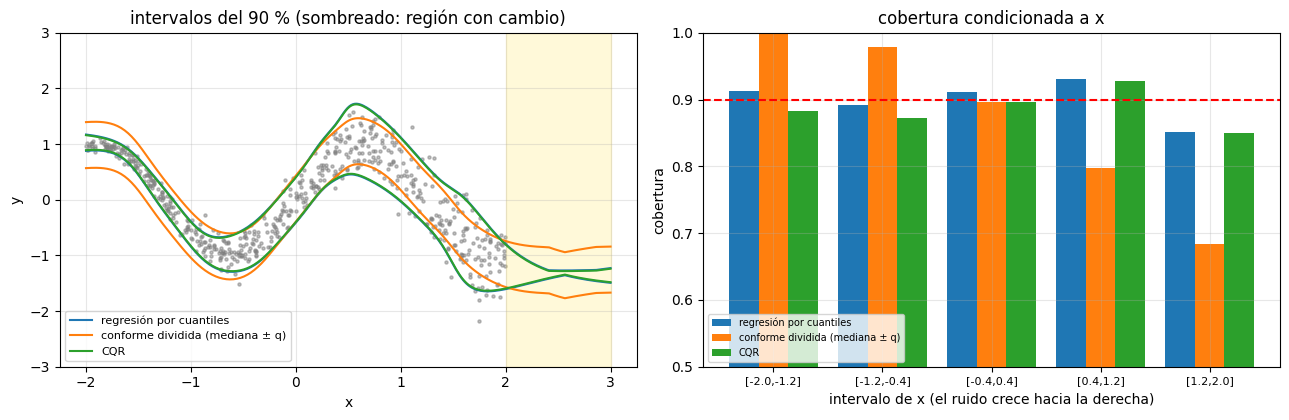

tiempo 18 s


In [7]:
t0 = time.time()
rg = np.random.default_rng(1)
def make_reg(n, lo, hi):
    x = rg.uniform(lo, hi, n); return x, f_true(x) + s_true(x) * rg.standard_normal(n)
xa, ya = make_reg(1000, -2, 2); xc, yc = make_reg(500, -2, 2); xe, ye = make_reg(5000, -2, 2); xs_, ys_ = make_reg(5000, 1, 3)
TAUS = torch.tensor([0.05, 0.5, 0.95])

def fit_quant(seed, steps=1200):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 3))
    opt = torch.optim.Adam(net.parameters(), lr=5e-3)
    X = torch.tensor(xa, dtype=torch.float32)[:, None]; Y = torch.tensor(ya, dtype=torch.float32)[:, None]
    for _ in range(steps):
        e = Y - net(X)
        loss = torch.maximum(TAUS * e, (TAUS - 1) * e).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return net

qnet = fit_quant(0)
def qpred(x):
    with torch.no_grad():
        q = qnet(torch.tensor(x, dtype=torch.float32)[:, None]).numpy()
    return np.sort(q, axis=1)                  # ordenar para evitar cuantiles que se cruzan
def conf_quantile(scores, alpha=0.1):
    n = len(scores); k = int(np.ceil((n + 1) * (1 - alpha))); return np.sort(scores)[min(k, n) - 1]

qc = qpred(xc)
Q_res = conf_quantile(np.abs(yc - qc[:, 1]))
Q_cqr = conf_quantile(np.maximum(qc[:, 0] - yc, yc - qc[:, 2]))
def intervals(x):
    q = qpred(x)
    return {"regresión por cuantiles": (q[:, 0], q[:, 2]),
            "conforme dividida (mediana ± q)": (q[:, 1] - Q_res, q[:, 1] + Q_res),
            "CQR": (q[:, 0] - Q_cqr, q[:, 2] + Q_cqr)}
bins = np.linspace(-2, 2, 6)
print(f"correcciones conformes: cuantil de residuos {Q_res:.3f}, corrección CQR {Q_cqr:+.3f}")
print(f"{'intervalo':30s} {'cobertura':>9s} {'ancho medio':>11s}   cobertura por intervalo de x (poco ruido ... mucho ruido)   {'cobertura, x en [1,3]':>22s}")
for name, (lo, hi) in intervals(xe).items():
    inside = (ye >= lo) & (ye <= hi)
    per_bin = [inside[(xe >= bins[b]) & (xe < bins[b + 1] + 1e-9)].mean() for b in range(5)]
    lo2, hi2 = intervals(xs_)[name]; cov_shift = ((ys_ >= lo2) & (ys_ <= hi2)).mean()
    print(f"{name:30s} {inside.mean():9.3f} {(hi - lo).mean():11.3f}   " + " ".join(f"{c:.2f}" for c in per_bin) + f"   {cov_shift:22.3f}")

xg2 = np.linspace(-2, 3, 300); iv = intervals(xg2)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].scatter(xe[:600], ye[:600], s=5, c="gray", alpha=0.5)
for k, (name, (lo, hi)) in enumerate(iv.items()):
    ax[0].plot(xg2, lo, c=f"C{k}", label=name); ax[0].plot(xg2, hi, c=f"C{k}")
ax[0].axvspan(2, 3, color="gold", alpha=0.15); ax[0].set_ylim(-3, 3); ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
ax[0].set_title("intervalos del 90 % (sombreado: región con cambio)"); ax[0].legend(fontsize=8, loc="lower left")
w = 0.27
for k, (name, (lo, hi)) in enumerate(intervals(xe).items()):
    inside = (ye >= lo) & (ye <= hi)
    ax[1].bar(np.arange(5) + (k - 1) * w, [inside[(xe >= bins[b]) & (xe < bins[b + 1] + 1e-9)].mean() for b in range(5)], width=w, color=f"C{k}", label=name)
ax[1].axhline(0.9, c="r", ls="--"); ax[1].set_xticks(range(5)); ax[1].set_xticklabels([f"[{bins[b]:.1f},{bins[b+1]:.1f}]" for b in range(5)], fontsize=8)
ax[1].set_ylim(0.5, 1.0); ax[1].set_xlabel("intervalo de x (el ruido crece hacia la derecha)"); ax[1].set_ylabel("cobertura"); ax[1].set_title("cobertura condicionada a x"); ax[1].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** Los tres intervalos alcanzan aproximadamente la cobertura nominal en promedio (regresión por cuantiles 0.900, CQR 0.886, conforme dividida 0.869; con 500 puntos de calibración un conjunto de calibración puede legítimamente quedar un par de puntos fuera, y 0.869 está en el borde de esa dispersión), y tienen un ancho medio parecido (0.81 a 0.84). **Condicionados a $x$ son muy distintos**: la conforme dividida con ancho constante cubre el 100 % en el intervalo más tranquilo y solo el 68 % en el más ruidoso, mientras que los intervalos basados en cuantiles adaptan su ancho y se mantienen entre 0.85 y 0.93 en cada intervalo. La corrección de CQR fue minúscula aquí (-0.012) porque la red de cuantiles ya estaba bien calibrada; su valor es la garantía, no un cambio en este ajuste concreto. En la región con cambio $x \in [1, 3]$, donde no hay datos de entrenamiento y el ruido sigue creciendo, **todos los métodos cubren solo 0.44 a 0.48**: ningún intervalo arregla la extrapolación, tampoco el conforme.

**En qué se diferencia el juguete de los sistemas reales.** Una dimensión de entrada permite inspeccionar fácilmente la cobertura condicional; en dimensiones altas no se puede agrupar por $x$, y la cobertura condicional exacta es imposible sin supuestos (resultado conocido), así que la práctica se apoya en métodos adaptativos como CQR más monitorización en subgrupos importantes.

## 8. Cambio de distribución: imágenes corrompidas

Hasta ahora "cambio" ha significado ruido añadido. Hendrycks y Dietterich (2019) lo convirtieron en un banco de pruebas: tomar un conjunto de prueba y aplicar **corrupciones** realistas (ruido, desenfoque, clima, artefactos digitales) con **severidad** creciente, y medir cómo se degradan la exactitud y la calibración. Aplicamos tres corrupciones a los dígitos de 8 por 8, cada una en seis severidades:

* **ruido gaussiano** con desviación típica de 0 a 0.5 (un sensor ruidoso);
* **desenfoque gaussiano** con ancho de 0 a 2.5 píxeles (una cámara desenfocada; en una imagen de 8 por 8 un ancho de 1.5 ya mezcla trazos vecinos);
* **rotación** de 0 a 60 grados (una cámara inclinada).

Comparamos la red simple con el conjunto de 5 miembros de la sección 4 en **exactitud** y **ECE**. Ovadia et al. (2019) informan que la calibración se degrada de forma constante con el cambio y que los conjuntos se degradan con más suavidad; lo comprobamos en este juguete.

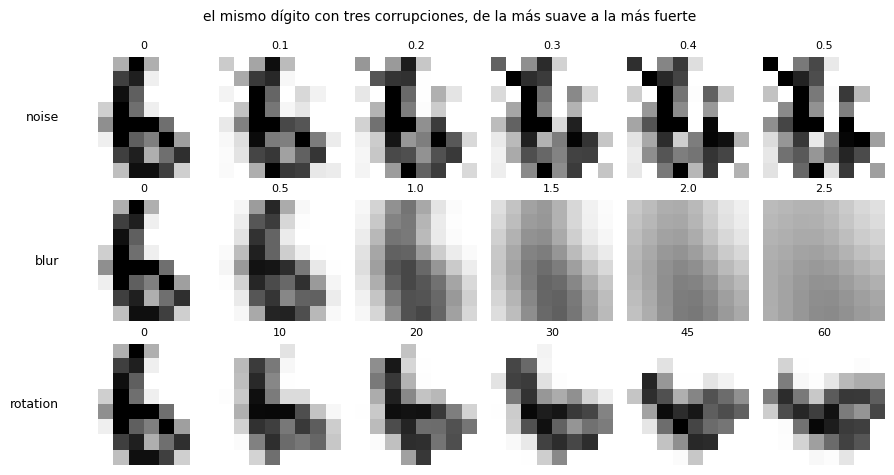

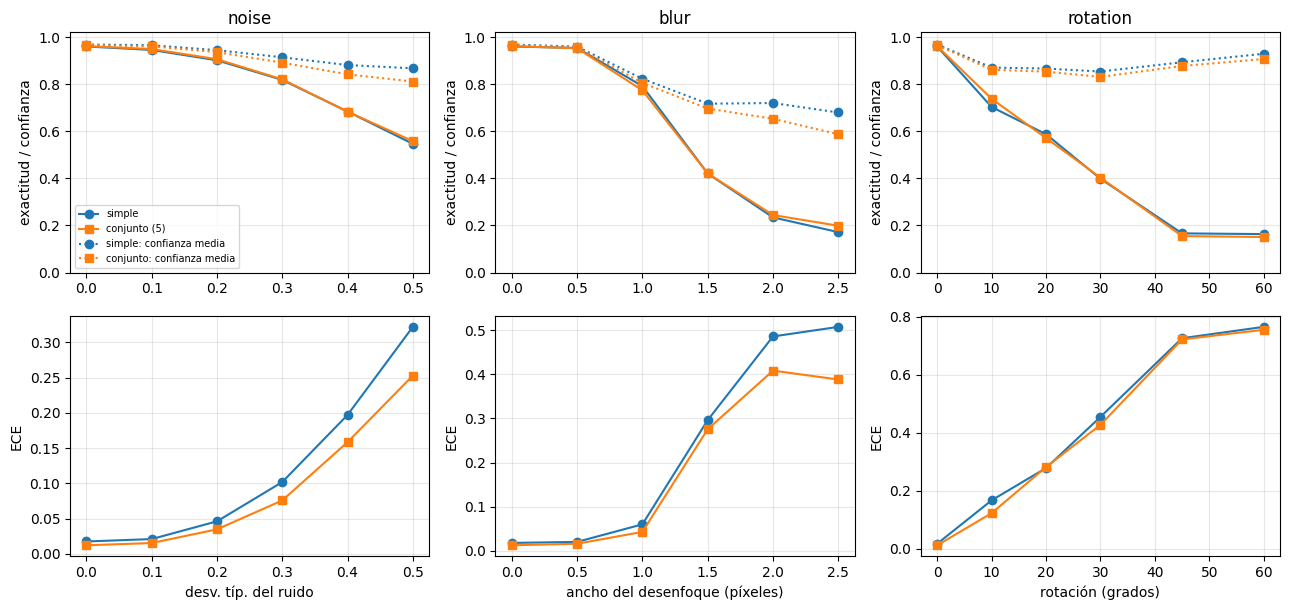

corrupción @ nivel        ex simple ECE simple  ex conj ECE conj
noise @ 0                     0.960      0.018    0.961    0.012
noise @ 0.3                   0.818      0.102    0.820    0.076
noise @ 0.5                   0.547      0.322    0.558    0.253
blur @ 0                      0.960      0.018    0.961    0.012
blur @ 1.5                    0.421      0.296    0.421    0.275
blur @ 2.5                    0.172      0.508    0.199    0.388
rotation @ 0                  0.960      0.018    0.961    0.012
rotation @ 30                 0.399      0.455    0.403    0.428
rotation @ 60                 0.163      0.766    0.151    0.756
tiempo 6 s


In [8]:
def corrupt_blur(X, sigma):
    if sigma == 0: return X
    return np.stack([ndimage.gaussian_filter(x.reshape(8, 8), sigma).reshape(-1) for x in X]).astype(np.float32)
def corrupt_rot(X, deg):
    if deg == 0: return X
    return np.stack([np.clip(ndimage.rotate(x.reshape(8, 8), deg, reshape=False, order=1, mode="constant"), 0, 1).reshape(-1) for x in X]).astype(np.float32)

CORR = {"noise": (lambda X, s: corrupt_noise(X, s, seed=3), [0, 0.1, 0.2, 0.3, 0.4, 0.5], "desv. típ. del ruido"),
        "blur": (corrupt_blur, [0, 0.5, 1.0, 1.5, 2.0, 2.5], "ancho del desenfoque (píxeles)"),
        "rotation": (corrupt_rot, [0, 10, 20, 30, 45, 60], "rotación (grados)")}

# algunos ejemplos
fig, ax = plt.subplots(3, 6, figsize=(9, 4.8))
for r, (name, (fn, levels, lab)) in enumerate(CORR.items()):
    for c, lv in enumerate(levels):
        ax[r, c].imshow(fn(Xpool[:1], lv).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[r, c].axis("off"); ax[r, c].set_title(f"{lv}", fontsize=8)
    ax[r, 0].text(-0.2, 0.5, name, transform=ax[r, 0].transAxes, ha="right", va="center", fontsize=9)
plt.suptitle("el mismo dígito con tres corrupciones, de la más suave a la más fuerte", fontsize=10); plt.tight_layout(); plt.show()

t0 = time.time()
def ens_probs(models, X): return np.mean([softmax_np(logits_of(m, X)) for m in models], 0)
shift_res = {}
for name, (fn, levels, lab) in CORR.items():
    rows = []
    for lv in levels:
        Xc = fn(Xpool, lv)
        p1, pe = softmax_np(logits_of(net10, Xc)), ens_probs(ens10, Xc)
        rows.append([(p1.argmax(1) == ypool).mean(), ece_score(p1, ypool), p1.max(1).mean(), (pe.argmax(1) == ypool).mean(), ece_score(pe, ypool), pe.max(1).mean()])
    shift_res[name] = np.array(rows)
fig, ax = plt.subplots(2, 3, figsize=(13, 6.2))
for j, (name, (fn, levels, lab)) in enumerate(CORR.items()):
    R = shift_res[name]
    ax[0, j].plot(levels, R[:, 0], "o-", label="simple"); ax[0, j].plot(levels, R[:, 3], "s-", label="conjunto (5)"); ax[0, j].plot(levels, R[:, 2], "o:", c="C0", label="simple: confianza media"); ax[0, j].plot(levels, R[:, 5], "s:", c="C1", label="conjunto: confianza media")
    ax[0, j].set_title(name); ax[0, j].set_ylabel("exactitud / confianza"); ax[0, j].set_ylim(0, 1.02)
    ax[1, j].plot(levels, R[:, 1], "o-", label="simple"); ax[1, j].plot(levels, R[:, 4], "s-", label="conjunto (5)"); ax[1, j].set_xlabel(lab); ax[1, j].set_ylabel("ECE")
ax[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"{'corrupción @ nivel':24s} {'ex simple':>10s} {'ECE simple':>10s} {'ex conj':>8s} {'ECE conj':>8s}")
for name, (fn, levels, lab) in CORR.items():
    for i in [0, 3, 5]:
        R = shift_res[name][i]
        print(f"{name + ' @ ' + str(levels[i]):24s} {R[0]:10.3f} {R[1]:10.3f} {R[3]:8.3f} {R[4]:8.3f}")
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** Las tres corrupciones destruyen la exactitud al crecer la severidad, y la confianza no la acompaña hacia abajo. El ruido 0.3 baja la exactitud de 0.96 a 0.82 y sube el ECE de 0.018 a 0.10; la rotación de 30 grados lleva la exactitud a 0.40 con ECE 0.46 (el modelo falla más de la mitad de las veces pero suena seguro); el desenfoque 1.5 da 0.42 y ECE 0.30. El conjunto está **mejor calibrado que la red simple en la mayoría de los casos** (ruido 0.5: ECE 0.25 frente a 0.32; desenfoque 2.5: 0.39 frente a 0.51) con la misma exactitud, pero en la rotación casi no da ventaja (0.43 frente a 0.46 a 30 grados). De acuerdo con Ovadia et al. (2019), un conjunto ayuda pero no rescata la calibración bajo cambio. Son ejecuciones únicas de un modelo entrenado, así que las diferencias pequeñas (por ejemplo en la exactitud) no son significativas.

**En qué se diferencia el juguete de los sistemas reales.** Las corrupciones aplicadas a una imagen de 64 píxeles son primas toscas de los 15 tipos de corrupción y 5 severidades del banco de pruebas real (Hendrycks y Dietterich, 2019), y los cambios reales a menudo **no** son una corrupción conocida sino una cámara, estación o población nueva. Por eso la monitorización en producción (sección 11) importa más que cualquier truco de robustez.

## 9. Ejemplos adversarios y entrenamiento adversario

Otro tipo de cambio es *deliberado*. Szegedy et al. (2014) hallaron que perturbaciones diminutas y cuidadosamente elegidas de una entrada pueden cambiar la predicción de una red. Goodfellow et al. (2015) explicaron por qué con un ataque de una línea. Sea $\mathcal L(x, y)$ la pérdida del modelo con la entrada $x$ y la etiqueta verdadera $y$. El **método del signo del gradiente rápido** (FGSM) mueve cada píxel $\varepsilon$ (épsilon, el presupuesto de perturbación) en la dirección que aumenta la pérdida:

$$x' = \mathrm{clip}_{[0,1]}\Big(x + \varepsilon \cdot \mathrm{sign}\big(\nabla_x \mathcal L(x, y)\big)\Big).$$

El **descenso de gradiente proyectado** (PGD, Madry et al., 2018) repite esto en $T$ pasos pequeños de tamaño $\eta$ (eta) desde un inicio aleatorio dentro de la región permitida, proyectando tras cada paso sobre el conjunto de imágenes a distancia $\varepsilon$ del original en cada píxel (la bola $\ell_\infty$, donde $\ell_\infty$ es el mayor cambio por píxel):

$$x^{t+1} = \Pi_{\|x'-x\|_\infty \le \varepsilon}\Big(x^t + \eta \cdot \mathrm{sign}\big(\nabla_x \mathcal L(x^t, y)\big)\Big).$$

PGD es un ataque más fuerte porque usa muchos pasos de gradiente en lugar de uno. El **entrenamiento adversario** (Madry et al., 2018) se defiende entrenando con la salida del atacante: en cada paso se generan ejemplos PGD contra el modelo actual y se minimiza la pérdida en **ellos**. Esto cuesta una pasada hacia adelante y atrás extra por paso de ataque. Medimos: la exactitud frente a $\varepsilon$ para FGSM y PGD en la red estándar, luego el entrenamiento adversario con $\varepsilon = 0.1$ (unos 1.6 niveles de gris de 16, con píxeles escalados a $[0,1]$), su coste en exactitud y su coste en **tiempo**.

tiempo de entrenamiento: estándar 1.6 s, adversario 5.7 s  (x3.5)
  eps  estándar FGSM  estándar PGD   adversario FGSM   adversario PGD
 0.00          0.960         0.960             0.972            0.972
 0.02          0.906         0.905             0.951            0.951
 0.05          0.753         0.748             0.917            0.914
 0.10          0.332         0.300             0.773            0.752
 0.15          0.059         0.037             0.548            0.497
 0.20          0.007         0.000             0.289            0.180
 0.30          0.002         0.000             0.002            0.000


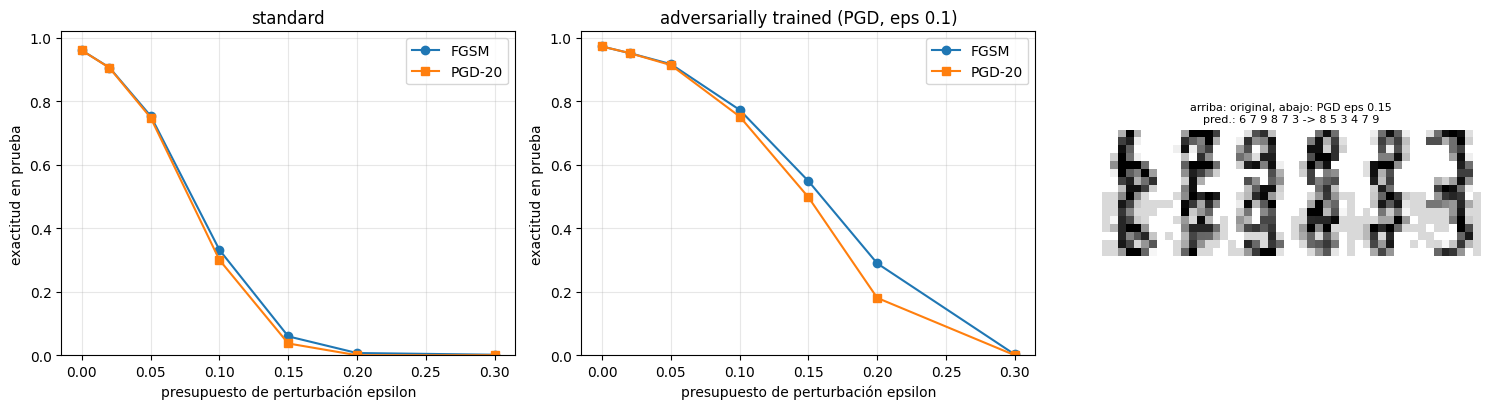

tiempo 16 s


In [9]:
def fgsm(model, X, y, eps):
    x = torch.as_tensor(X, dtype=torch.float32).clone().requires_grad_(True)
    loss = F.cross_entropy(model(x), torch.as_tensor(y))
    g, = torch.autograd.grad(loss, x)
    return (x + eps * g.sign()).clamp(0, 1).detach()

def pgd(model, X, y, eps, steps=20, seed=0):
    X0 = torch.as_tensor(X, dtype=torch.float32); yt_ = torch.as_tensor(y); alpha = 2.5 * eps / steps
    g = torch.Generator().manual_seed(seed)
    x = (X0 + (torch.rand(X0.shape, generator=g) * 2 - 1) * eps).clamp(0, 1)
    for _ in range(steps):
        x.requires_grad_(True)
        loss = F.cross_entropy(model(x), yt_)
        grad, = torch.autograd.grad(loss, x)
        x = x.detach() + alpha * grad.sign()
        x = torch.min(torch.max(x, X0 - eps), X0 + eps).clamp(0, 1)          # proyectar sobre la bola eps y los píxeles válidos
    return x.detach()

def adv_fit(X, y, seed, eps=0.1, steps=5, epochs=100, lr=3e-3, d_out=10):
    torch.manual_seed(seed)
    m = make_mlp(d_out); opt = torch.optim.Adam(m.parameters(), lr=lr); yt_ = torch.as_tensor(y)
    for e in range(epochs):
        m.eval(); xa_ = pgd(m, X, y, eps, steps, seed=e); m.train()
        loss = F.cross_entropy(m(xa_), yt_)
        opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

def acc_on(model, X, y):
    with torch.no_grad(): return float((model(torch.as_tensor(X, dtype=torch.float32)).argmax(1).numpy() == y).mean())

t0 = time.time()
tt = time.time(); _ = fit(X10, y10, seed=0); t_std = time.time() - tt
tt = time.time(); net_adv = adv_fit(X10, y10, seed=0); t_adv = time.time() - tt
eps_list = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
Xt_, yt10 = Xpool, ypool
curves = {}
for name, mdl in [("standard", net10), ("adversarially trained (PGD, eps 0.1)", net_adv)]:
    curves[name] = {"FGSM": [acc_on(mdl, fgsm(mdl, Xt_, yt10, e).numpy(), yt10) for e in eps_list],
                    "PGD": [acc_on(mdl, pgd(mdl, Xt_, yt10, e, 20).numpy(), yt10) for e in eps_list]}
print(f"tiempo de entrenamiento: estándar {t_std:.1f} s, adversario {t_adv:.1f} s  (x{t_adv / t_std:.1f})")
print(f"{'eps':>5s} {'estándar FGSM':>14s} {'estándar PGD':>13s} {'adversario FGSM':>17s} {'adversario PGD':>16s}")
for i, e in enumerate(eps_list):
    c1, c2 = curves["standard"], curves["adversarially trained (PGD, eps 0.1)"]
    print(f"{e:5.2f} {c1['FGSM'][i]:14.3f} {c1['PGD'][i]:13.3f} {c2['FGSM'][i]:17.3f} {c2['PGD'][i]:16.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
for k, (name, c) in enumerate(curves.items()):
    ax[k].plot(eps_list, c["FGSM"], "o-", label="FGSM"); ax[k].plot(eps_list, c["PGD"], "s-", label="PGD-20")
    ax[k].set_title(name); ax[k].set_xlabel("presupuesto de perturbación epsilon"); ax[k].set_ylabel("exactitud en prueba"); ax[k].set_ylim(0, 1.02); ax[k].legend()
ex = np.arange(6)
xadv = pgd(net10, Xt_[ex], yt10[ex], 0.15, 20).numpy()
with torch.no_grad(): pa = net10(torch.as_tensor(xadv)).argmax(1).numpy(); p0 = net10(torch.as_tensor(Xt_[ex])).argmax(1).numpy()
ax[2].axis("off"); sub = ax[2].inset_axes([0, 0, 1, 1]); sub.axis("off")
strip = np.concatenate([np.concatenate([Xt_[i].reshape(8, 8) for i in ex], 1), np.concatenate([xadv[j].reshape(8, 8) for j in range(6)], 1)], 0)
sub.imshow(strip, cmap="gray_r", vmin=0, vmax=1); sub.set_title("arriba: original, abajo: PGD eps 0.15\npred.: " + " ".join(map(str, p0)) + " -> " + " ".join(map(str, pa)), fontsize=8)
plt.tight_layout(); plt.show()
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** La red estándar es frágil: con un presupuesto de solo 0.05 por píxel la exactitud cae de 0.96 a 0.75, con 0.1 a 0.33 (FGSM) y 0.30 (PGD), y PGD con 0.2 la lleva exactamente a 0. PGD es más fuerte que FGSM, más aún al crecer epsilon. El **entrenamiento adversario** (PGD de 5 pasos con epsilon 0.1) mantiene 0.75 de exactitud frente a PGD-20 con epsilon 0.1 (frente a 0.30) y 0.50 con 0.15, y **no costó exactitud limpia aquí** (0.972 frente a 0.960; en este conjunto diminuto los datos perturbados extra probablemente actúan como regularización, con una sola semilla, así que no generalices). No ayuda más allá de su presupuesto de entrenamiento: con epsilon 0.3 ambas redes están en 0. El **coste** es tiempo: 7.0 s frente a 1.1 s para entrenar, 6.2 veces más, lo que coincide con los 5 pasos de ataque más la actualización.

**En qué se diferencia el juguete de los sistemas reales.** Un dígito de 8 por 8 con una red multicapa pequeña es fácil de atacar y barato de entrenar de forma adversaria. En imágenes del tamaño de ImageNet el mismo presupuesto de perturbación es invisible al ojo, el entrenamiento adversario cuesta de 5 a 10 veces más cómputo y el precio en exactitud es mayor. Además, PGD con un solo inicio aleatorio da solo una *cota superior* de la exactitud robusta: conjuntos de ataques más fuertes (por ejemplo AutoAttack) pueden bajarla más, y una defensa que solo oculta los gradientes puede parecer robusta a FGSM y fallar ante mejores ataques (**enmascaramiento de gradientes**).

## 10. Aumento de datos como herramienta de robustez

La herramienta de robustez más barata es la del módulo 03 de Neural Networks 1001: **aumentar los datos de entrenamiento** con las variaciones que esperas en la prueba. Aquí entrenamos la misma red con los 500 dígitos de entrenamiento más 6 copias corrompidas al azar de cada uno (ruido con desviación típica uniforme de 0 a 0.4 y una rotación uniforme entre -30 y +30 grados). Luego probamos con:

* ruido 0.3 y rotación de 30 grados: corrupciones **vistas** en el aumento;
* **desenfoque 1.5**: una corrupción que el aumento **nunca usó**, para ver si la robustez se generaliza;
* **FGSM y PGD con epsilon 0.1**: ataques adversarios, contra la red estándar, la aumentada y la entrenada de forma adversaria de la sección 9.

La pregunta es si la robustez a una familia se traslada a otra.

conjunto de entrenamiento aumentado: 3500 imágenes, entrenado en 7 s


modelo                                    limpio   ruido 0.3 (visto) rotación 30 (vista) desenfoque 1.5 (no visto)            FGSM 0.1          PGD-20 0.1


estándar                                   0.960               0.818               0.399               0.421               0.332               0.300


aumentada (ruido+rotación)                 0.950               0.758               0.839               0.372               0.290               0.242


adversaria (PGD 0.1)                       0.972               0.882               0.473               0.628               0.773               0.752


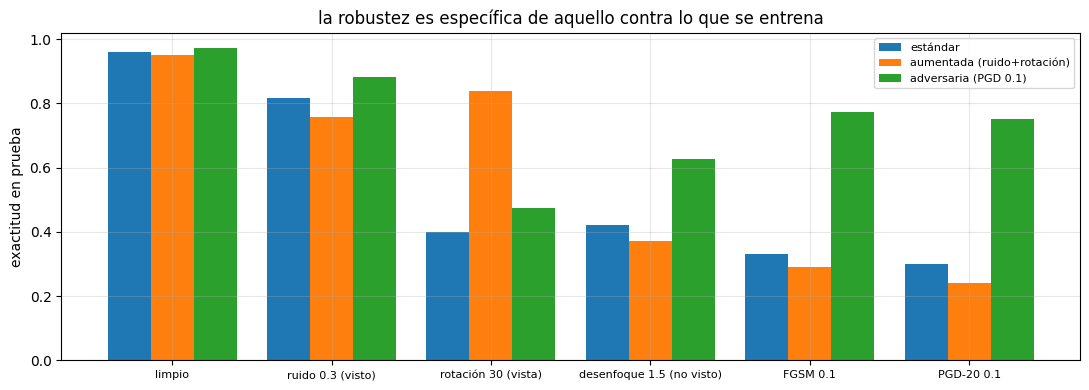

In [10]:
t0 = time.time()
ra = np.random.default_rng(5)
def augment(X, copies=6):
    out = [X]
    for _ in range(copies):
        Xc = np.stack([corrupt_noise(x[None], ra.uniform(0, 0.4), seed=int(ra.integers(1e9)))[0] for x in X])
        Xc = np.stack([corrupt_rot(x[None], float(ra.uniform(-30, 30)))[0] for x in Xc])
        out.append(Xc)
    return np.concatenate(out).astype(np.float32)
X_aug = augment(X10); y_aug = np.tile(y10, 7)
net_aug = fit(X_aug, y_aug, seed=0)
print(f"conjunto de entrenamiento aumentado: {len(X_aug)} imágenes, entrenado en {time.time() - t0:.0f} s")

tests = {"limpio": Xpool, "ruido 0.3 (visto)": corrupt_noise(Xpool, 0.3, 3), "rotación 30 (vista)": corrupt_rot(Xpool, 30), "desenfoque 1.5 (no visto)": corrupt_blur(Xpool, 1.5)}
models = {"estándar": net10, "aumentada (ruido+rotación)": net_aug, "adversaria (PGD 0.1)": net_adv}
print(f"{'modelo':28s} " + " ".join(f"{k:>19s}" for k in list(tests) + ["FGSM 0.1", "PGD-20 0.1"]))
rob = {}
for name, mdl in models.items():
    accs = [acc_on(mdl, X, ypool) for X in tests.values()]
    accs += [acc_on(mdl, fgsm(mdl, Xpool, ypool, 0.1).numpy(), ypool), acc_on(mdl, pgd(mdl, Xpool, ypool, 0.1, 20).numpy(), ypool)]
    rob[name] = accs
    print(f"{name:28s} " + " ".join(f"{a:19.3f}" for a in accs))

fig, ax = plt.subplots(figsize=(11, 4))
labels = list(tests) + ["FGSM 0.1", "PGD-20 0.1"]; wd = 0.27
for k, (name, accs) in enumerate(rob.items()):
    ax.bar(np.arange(len(labels)) + (k - 1) * wd, accs, width=wd, label=name)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8); ax.set_ylabel("exactitud en prueba"); ax.set_ylim(0, 1.02); ax.legend(fontsize=8, loc="upper right")
ax.set_title("la robustez es específica de aquello contra lo que se entrena"); plt.tight_layout(); plt.show()

**Lectura.** La robustez es **específica de aquello contra lo que entrenas**. Aumentar con ruido y rotación subió la rotación 30 de 0.40 a 0.84, una gran mejora, pero **no** ayudó con el ruido 0.3 que también vio (0.76 frente a 0.82 de la red estándar: el modelo se entrenó con una mezcla amplia de ruido y rotación, lo que costó algo de exactitud en cada una) y perjudicó al desenfoque no visto (0.37 frente a 0.42) y a los ataques adversarios (0.24 con PGD frente a 0.30). La red entrenada de forma adversaria, en cambio, fue también más robusta al ruido 0.3 (0.88) y al desenfoque (0.63), corrupciones que nunca vio, además de su ataque objetivo; pero apenas ayudó con la rotación (0.47). Así que ningún método único cubre todos los cambios; elige los aumentos según los cambios que esperas, prueba con cambios con los que no entrenaste y recuerda que todo esto es de una semilla por modelo.

## 11. Una lista de comprobación para producción

Una confianza es una funcionalidad de producto con modos de fallo, no un subproducto gratuito de la softmax. Antes de ponerla delante de un usuario o de un sistema posterior:

1. **Di qué significa el número.** ¿"Probabilidad de que la etiqueta sea correcta", "intervalo que contiene el 90 % de los resultados" o "puntuación de orden"? Solo los dos primeros se pueden auditar.
2. **Aparta datos para calibrar y no los reutilices** para parada temprana ni para elegir modelo. Ajusta $T$ (o el cuantil conforme) ahí e informa el ECE y la NLL en un tercer conjunto intacto.
3. **Mide la calibración donde se usará el modelo**, por subgrupo y por segmento (periodo, dispositivo, región). La calibración global puede ocultar un subgrupo muy desviado.
4. **Elige la herramienta según la necesidad.** Mejores probabilidades: primero escalado por temperatura (gratis), luego conjuntos. Cobertura garantizada: conforme. Intervalos adaptativos en regresión: CQR. Detección de entradas nuevas: la discrepancia del conjunto, con la MSP como referencia a superar.
5. **Planifica el cambio.** Registra la confianza, monitoriza su distribución y la cobertura en un flujo de muestras etiquetadas, y pon una alarma cuando se muevan. Recalibra (la sección 6 mostró que restablece la cobertura) cuando lleguen etiquetas.
6. **Define la vía de abstención.** Una opción de rechazo solo sirve si al otro lado espera una persona, un modelo más lento o una opción segura por defecto, y se contabiliza el coste de abstenerse.
7. **Decide el modelo de amenaza.** Si nadie adversario puede tocar la entrada, las corrupciones y el aumento son las pruebas relevantes; si puede, añade la evaluación de ataques (al menos PGD, mejor conjuntos más fuertes) y acepta el coste en exactitud y cómputo del entrenamiento adversario.
8. **Presupuesta el coste.** Un conjunto de $M$ cuesta $M$ veces el cómputo; el dropout MC $S$ veces al predecir; la conforme y el escalado por temperatura son casi gratis. Elige el método más barato que cumpla el requisito medido.
9. **Vuelve a medir tras cada reentrenamiento.** La calibración es una propiedad de un modelo entrenado, no de la arquitectura.
10. **Comunica con honestidad.** Muestra conjuntos o intervalos en lugar de un único número falsamente preciso, y anota las condiciones (datos, rango de cambio, nivel de cobertura) bajo las que se midió la garantía.

## Ideas clave

* Una predicción necesita una confianza que **signifique algo**. Exactitud y calibración son propiedades distintas; las confianzas calibradas permiten umbrales, traspasos y poner precio al riesgo.
* La incertidumbre **aleatoria** (ruido en los datos) no disminuye con más datos y una red puede aprenderla; la **epistémica** (aquí no hay datos) aparece como discrepancia entre modelos plausibles, grande en huecos y fuera del rango de entrenamiento (sección 2).
* Las redes entrenadas para memorizar son **demasiado confiadas**; el **escalado por temperatura** con un solo número ajustado redujo el ECE sin cambiar una sola predicción (sección 3). No sabe *dónde* está inseguro el modelo.
* Los **conjuntos, el dropout MC y Laplace** dan incertidumbre dependiente de la entrada. En nuestro juguete el orden no fue uniforme entre criterios, y las diferencias entre métodos estaban a menudo dentro del ruido de semillas (sección 4); los conjuntos cuestan $M$ veces más.
* La **predicción selectiva** convierte la confianza en intercambios de exactitud por cobertura (sección 5).
* La **predicción conforme** dio una cobertura **medida** del 90 % para cualquier modelo, con una dispersión Beta entre conjuntos de calibración, y la perdió bajo cambio hasta que recalibramos (sección 6). **CQR** mantuvo la garantía y adaptó su ancho al ruido (sección 7).
* El **cambio de distribución** degradó juntas la exactitud y la calibración; la confianza siguió demasiado alta (sección 8).
* Los **ejemplos adversarios** hunden una red estándar con presupuestos diminutos; **PGD** es más fuerte que FGSM; el entrenamiento adversario compra robustez con un coste medido en tiempo y exactitud limpia (sección 9).
* El **aumento** solo es robusto frente a aquello con lo que aumentas (sección 10). Monitoriza, recalibra y pon en tu proyecto la lista de la sección 11.

## Ejercicios

1. En la sección 2, da a los datos de entrenamiento un segundo hueco en $x \in [1.2, 1.5]$. ¿Sube ahí la desviación típica epistémica, y cómo cambia con $M = 2, 5, 12$?
2. En la sección 3, entrena con etiquetas limpias en lugar de un 25 % erróneas. ¿Cómo cambian la $T$ ajustada, el ECE antes y después y el diagrama de fiabilidad? Luego ajusta $T$ en el *conjunto de prueba ruidoso* de la sección 8 (ruido 0.3) y compruébala con imágenes rotadas.
3. En la sección 4, añade un **conjunto con temperatura escalada** y una **red simple con regularización de pesos**. ¿Alguno iguala al conjunto en el AUROC OOD? Usa 5 semillas en lugar de 3.
4. En la sección 5, ordena por la información mutua (para el conjunto) en lugar de la máxima probabilidad. ¿Cuál da mejor exactitud al 80 % de cobertura?
5. En la sección 6, cambia $\alpha$ a 0.05 y el tamaño de calibración a 50. Compara la dispersión de cobertura medida con la banda Beta. Luego implementa la puntuación de **conjuntos de predicción adaptativos** (suma de las probabilidades ordenadas hasta la clase verdadera) y compara los tamaños de conjunto.
6. En la sección 7, haz regresión por cuantiles con 5 000 puntos de entrenamiento pero solo 100 de calibración. ¿Qué pasa con la corrección de CQR y con la cobertura en cada intervalo?
7. En la sección 8, añade una corrupción de **brillo** (suma una constante a todos los píxeles) y una **traslación** de 1 píxel. ¿Cuál perjudica más, y sigue ayudando el conjunto?
8. En la sección 9, entrena de forma adversaria con $\varepsilon = 0.2$ y compara la exactitud limpia, la curva PGD y el tiempo de entrenamiento. Luego evalúa con 100 pasos PGD para comprobar que la exactitud robusta no baja (una comprobación contra el enmascaramiento de gradientes).
9. En la sección 10, añade desenfoque al aumento y vuelve a probar con rotación 45 (no vista). ¿Es siempre mejor la red aumentada con el rango más amplio, y qué cuesta en exactitud limpia?
10. Toma cualquier clasificador que hayas usado, aparta el 20 % de sus datos para calibración conforme e informa el tamaño medio de conjunto y la cobertura medida con un rango del 5 al 95 %.

## Referencias

* Alpaydin, E. y Kaynak, C. (1998). Optical Recognition of Handwritten Digits (UCI Machine Learning Repository, CC BY 4.0). https://doi.org/10.24432/C50P49
* Guo, C., Pleiss, G., Sun, Y. y Weinberger, K. Q. (2017). On calibration of modern neural networks. ICML. arXiv:1706.04599: https://arxiv.org/abs/1706.04599
* Lakshminarayanan, B., Pritzel, A. y Blundell, C. (2017). Simple and scalable predictive uncertainty estimation using deep ensembles. NeurIPS. arXiv:1612.01474: https://arxiv.org/abs/1612.01474
* Gal, Y. y Ghahramani, Z. (2016). Dropout as a Bayesian approximation: representing model uncertainty in deep learning. ICML. arXiv:1506.02142: https://arxiv.org/abs/1506.02142
* Kendall, A. y Gal, Y. (2017). What uncertainties do we need in Bayesian deep learning for computer vision? NeurIPS. arXiv:1703.04977: https://arxiv.org/abs/1703.04977
* Daxberger, E. et al. (2021). Laplace Redux: effortless Bayesian deep learning. NeurIPS. arXiv:2106.14806: https://arxiv.org/abs/2106.14806
* Hendrycks, D. y Gimpel, K. (2017). A baseline for detecting misclassified and out-of-distribution examples in neural networks. ICLR. arXiv:1610.02136: https://arxiv.org/abs/1610.02136
* Geifman, Y. y El-Yaniv, R. (2017). Selective classification for deep neural networks. NeurIPS. arXiv:1705.08500: https://arxiv.org/abs/1705.08500
* Angelopoulos, A. N. y Bates, S. (2021). A gentle introduction to conformal prediction and distribution-free uncertainty quantification. arXiv:2107.07511: https://arxiv.org/abs/2107.07511
* Koenker, R. y Bassett, G. (1978). Regression quantiles. *Econometrica* 46(1), 33-50: https://doi.org/10.2307/1913643
* Romano, Y., Patterson, E. y Candes, E. (2019). Conformalized quantile regression. NeurIPS. arXiv:1905.03222: https://arxiv.org/abs/1905.03222
* Hendrycks, D. y Dietterich, T. (2019). Benchmarking neural network robustness to common corruptions and perturbations. ICLR. arXiv:1903.12261: https://arxiv.org/abs/1903.12261
* Ovadia, Y. et al. (2019). Can you trust your model's uncertainty? Evaluating predictive uncertainty under dataset shift. NeurIPS. arXiv:1906.02530: https://arxiv.org/abs/1906.02530
* Szegedy, C. et al. (2014). Intriguing properties of neural networks. ICLR. arXiv:1312.6199: https://arxiv.org/abs/1312.6199
* Goodfellow, I. J., Shlens, J. y Szegedy, C. (2015). Explaining and harnessing adversarial examples. ICLR. arXiv:1412.6572: https://arxiv.org/abs/1412.6572
* Madry, A., Makelov, A., Schmidt, L., Tsipras, D. y Vladu, A. (2018). Towards deep learning models resistant to adversarial attacks. ICLR. arXiv:1706.06083: https://arxiv.org/abs/1706.06083

In [11]:
print(f"tiempo total de ejecución del cuaderno: {time.time() - T_START:.0f} s")

tiempo total de ejecución del cuaderno: 168 s
